## Data Preprocessing & Exploratory Data Analysis (EDA)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
#get raw data
data = pd.read_csv('./../data/raw/spotify_songs.csv')

## Exploratory Data Analysis

The dataset contains 18454 rows, with each row representing a unique track and it’s attributes. The
dataset contains 25 columns or attributes for each track, with 21 numerical (decimal and integer
types) columns and 4 columns of string data type. There are a mix of numerical and categorical
data types. The songs in the dataset are tracks coming from 6031 different musical artists.

Some of the features include:
full lyrics for each track,
decimal values ranging from 0-100 representing the popularity of a track,
track name,
album
and
artists (all also with corresponding
ids),
track release date,
and different audio features. Some of the audio features include track
duration, energy, loudness, mode, tempo, danceability and acousticness. Our target variable is the
track popularity score.


In [2]:
print(f"The list of all the columns in the dataset is: {list(data.columns)}")
print(f"The shape of the dataset is: {data.shape}")

The list of all the columns in the dataset is: ['track_id', 'track_name', 'track_artist', 'lyrics', 'track_popularity', 'track_album_id', 'track_album_name', 'track_album_release_date', 'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'language']
The shape of the dataset is: (18454, 25)


In [3]:
for col in data.columns:
    missing_count = data[col].isnull().sum()
    if missing_count > 0:
        print(f"Column '{col}' has {missing_count} missing values.")

Column 'lyrics' has 260 missing values.
Column 'language' has 260 missing values.


In [4]:
data[data['lyrics'].isnull() & (data['language'].isnull())]

,track_id,track_name,track_artist,lyrics,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,language
111,03bF2V5oDkhYDrMY6m7ZLB,Payback - Original Mix,Sandro Silva,NaN,25,2gTQ5glXXCHWIm1FIhyIXt,Payback,2013-11-25,Gym (Melbourne Bounce/Progressive House),5BqOZpVEqRDfZScvW1QUyA,...,-2.909,0,0.0526,0.000873,0.3840,0.1120,0.2300,127.870,277509,NaN
115,03L9G5TQGdhASEknspRIZQ,BARRACA (feat. MC Pikachu),Garmiani,NaN,50,2s4IDihyyANNAeV3eYnnwc,BARRACA (feat. MC Pikachu),2019-05-03,"Festival Music 2019 - Warm Up Music (EDM, Big ...",73uj4YmsC7SJ6SbUMTvf07,...,-1.262,0,0.0747,0.200000,0.3800,0.3510,0.9290,128.031,150020,NaN
125,03uSlN1JqW0MI6OCl7UQEa,You Don't Know,Psalm Trees,NaN,58,1ujIpuxtWkMjAnVn1QeFvt,You Don't Know What Love Is,2019-08-30,Lo-Fi Beats,37i9dQZF1DWWQRwui0ExPn,...,-8.706,0,0.0470,0.673000,0.8490,0.1430,0.8210,88.015,166364,NaN
199,05UpUTOoVV6PVjfIhjretZ,Conte a Todos,Sango,NaN,41,5Olya3n1lRhRU7NxNihquQ,"De Mim, Pra Você",2017-03-15,POPTIMISM,6lWMi4lPiiPwDqn8ZpeyAY,...,-5.412,0,0.3020,0.144000,0.1900,0.3380,0.6340,130.067,192000,NaN
465,0BjvqQdUUB2WzUncxxvIRh,entheogen,Nohidea,NaN,52,1wHWgiK24ERtcIGFN0eBK3,Departures,2018-08-18,Lofi Hip-Hop,37i9dQZF1DX36Xw4IJIVKA,...,-10.338,0,0.0621,0.258000,0.0075,0.1340,0.0853,78.305,108942,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17963,7o2SgrTlLry8e0pHJrdqQ5,My Sunshine,Kavv,NaN,51,6oFBUoIrI1Qnm5uFJsvJZQ,Cruise Control,2017-12-01,Sunny Beats,37i9dQZF1DXbtuVQL4zoey,...,-10.311,0,0.0710,0.933000,0.9080,0.1110,0.9320,144.360,106667,NaN
18077,7qoyy6rBNCGN27vOEZKgbr,Say U Won't,Brasstracks,NaN,40,4dj2CRLWvdFgEzsVtc2qr6,Good Love,2016-08-19,Urban Contemporary,4425cRh83Uzor4qCRfM9lb,...,-5.114,1,0.1540,0.001760,0.9100,0.0842,0.6290,148.992,189945,NaN
18081,7qrBYrivpvfXUPBMmqh3dA,5:32pm,The Deli,NaN,70,5GlqARIKJdOkuXKgvdouwz,Vibes 2,2016-10-17,Sunny Beats,37i9dQZF1DXbtuVQL4zoey,...,-13.672,0,0.0487,0.686000,0.9340,0.0762,0.5480,86.383,136914,NaN
18146,7sCIdsYQ8Nxoj6TjB1Eb7P,Toulouse - Original Mix,Nicky Romero,NaN,0,6FypcAZhJmCJJB8yEajt71,Toulouse,2012-01-02,2011-2014 House,53Ga3Xt9fumdJfhNNSBvzU,...,-3.842,0,0.1010,0.033800,0.6900,0.2180,0.2660,128.001,365626,NaN


### Visualizing distribution of popularity, genre, languages, and track durations


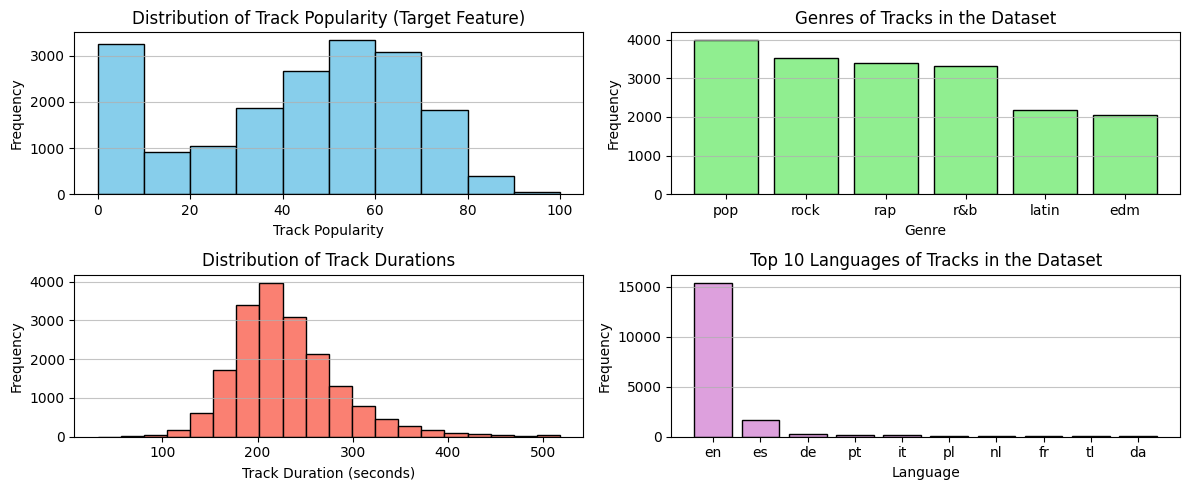

In [5]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 5))
# plot histogram for track popularity
ax[0,0].hist(data['track_popularity'].dropna(), bins=10, color='skyblue', edgecolor='black')
ax[0,0].set_title('Distribution of Track Popularity (Target Feature)')
ax[0,0].set_xlabel('Track Popularity')
ax[0,0].set_ylabel('Frequency')
ax[0,0].grid(axis='y', alpha=0.75)


#plot genre distribution
genre_counts = data['playlist_genre'].value_counts()
ax[0,1].bar(genre_counts.index,  genre_counts.values, color='lightgreen', edgecolor='black')
ax[0,1].set_title('Genres of Tracks in the Dataset')
ax[0,1].set_xlabel('Genre')
ax[0,1].set_ylabel('Frequency')
ax[0,1].grid(axis='y', alpha=0.75)  

# plot song durations (in seconds)
ax[1,0].hist(data['duration_ms'].dropna() / 1000, bins=20, color='salmon', edgecolor='black')
ax[1,0].set_title('Distribution of Track Durations')
ax[1,0].set_xlabel('Track Duration (seconds)')
ax[1,0].set_ylabel('Frequency')
ax[1,0].grid(axis='y', alpha=0.75)

# plot language distribution
language_counts = data['language'].value_counts().head(10) # top 10 languages
ax[1,1].bar(language_counts.index, language_counts.values, color='plum', edgecolor='black')
ax[1,1].set_title('Top 10 Languages of Tracks in the Dataset')
ax[1,1].set_xlabel('Language')
ax[1,1].set_ylabel('Frequency')
ax[1,1].grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

In [6]:
print("Number of songs in the dataset by language:", data['language'].unique(), "which means a total of ", len(data['language'].unique()), "different languages.")


Number of songs in the dataset by language: ['tl' 'en' 'it' 'es' 'et' 'fr' 'pl' 'nl' 'pt' nan 'id' 'de' 'no' 'da' 'ko'
 'ro' 'cy' 'sw' 'vi' 'so' 'tr' 'ru' 'sv' 'ja' 'hi' 'ar' 'cs' 'ca' 'hu'
 'sq' 'af' 'hr' 'el' 'fi' 'sk'] which means a total of  35 different languages.


### Lyrics word count distributions


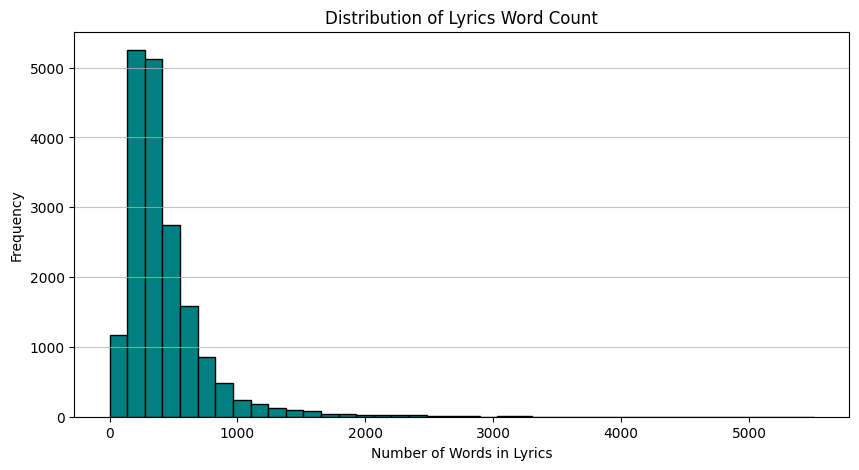

In [7]:
# Lyrics word count distributions, split by spaces
lyrics_word_count = data[~data["lyrics"].isna()]["lyrics"].map(lambda x: len(x.split()))

data["lyric_words"] = lyrics_word_count

plt.figure(figsize=(10, 5))
plt.hist(lyrics_word_count, bins=40, color='teal', edgecolor='black')
plt.title('Distribution of Lyrics Word Count')
plt.xlabel('Number of Words in Lyrics')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()


### Visualizing the distributions of attributes: 'danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'

The box plot for all them are shown below, and additional histograms are created for attributes with a lot of outliers or with a large variance in the outliers.


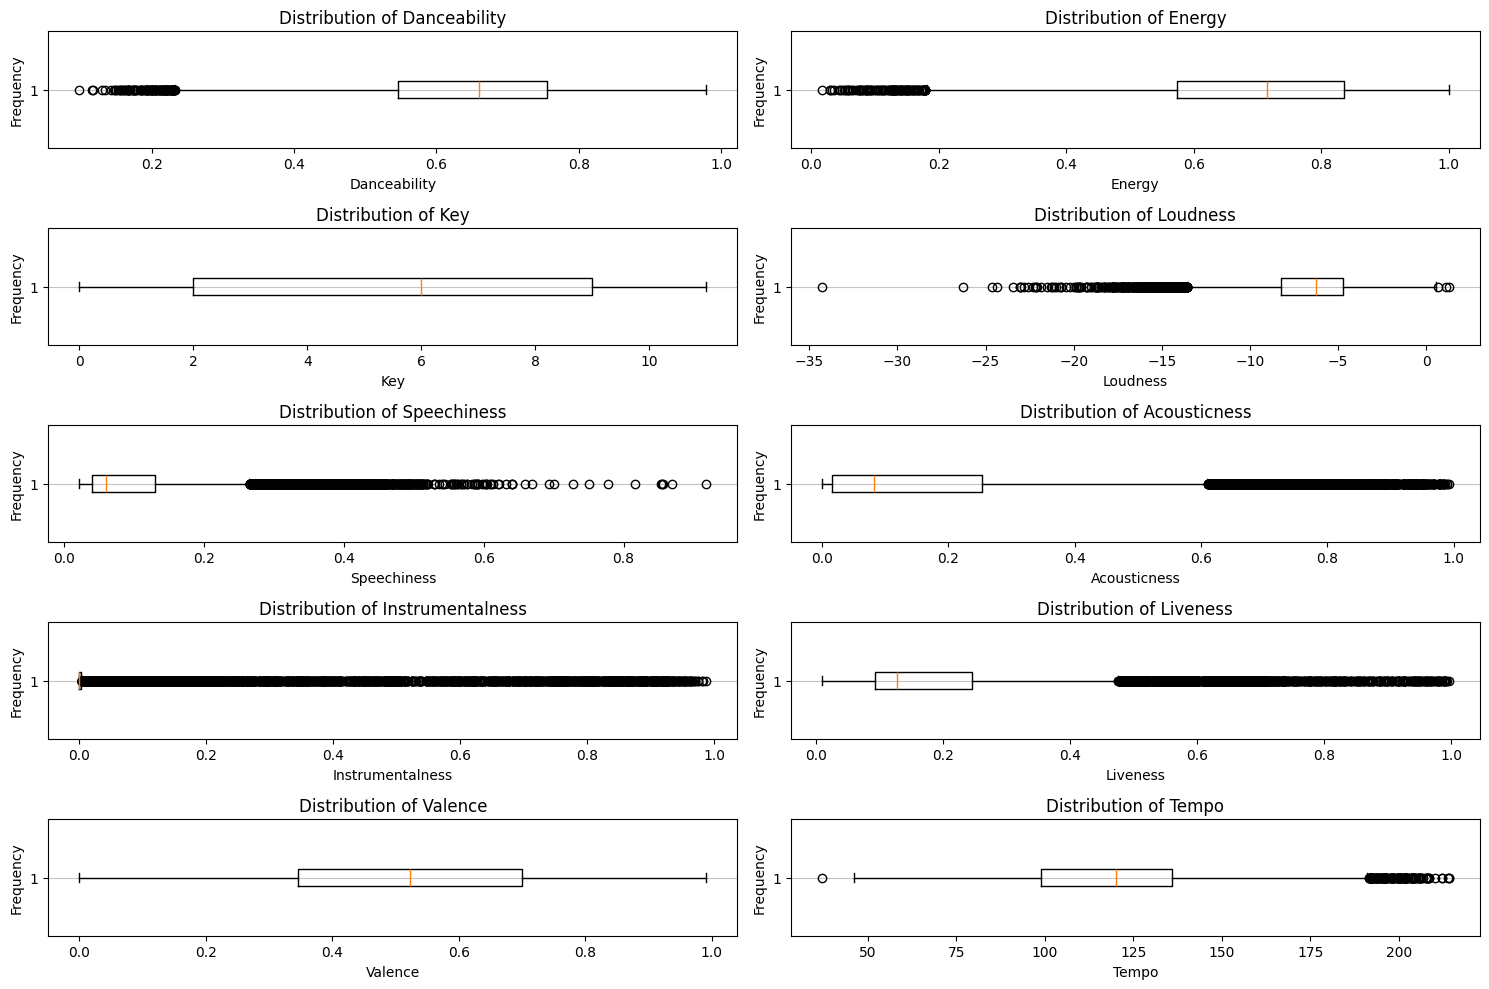

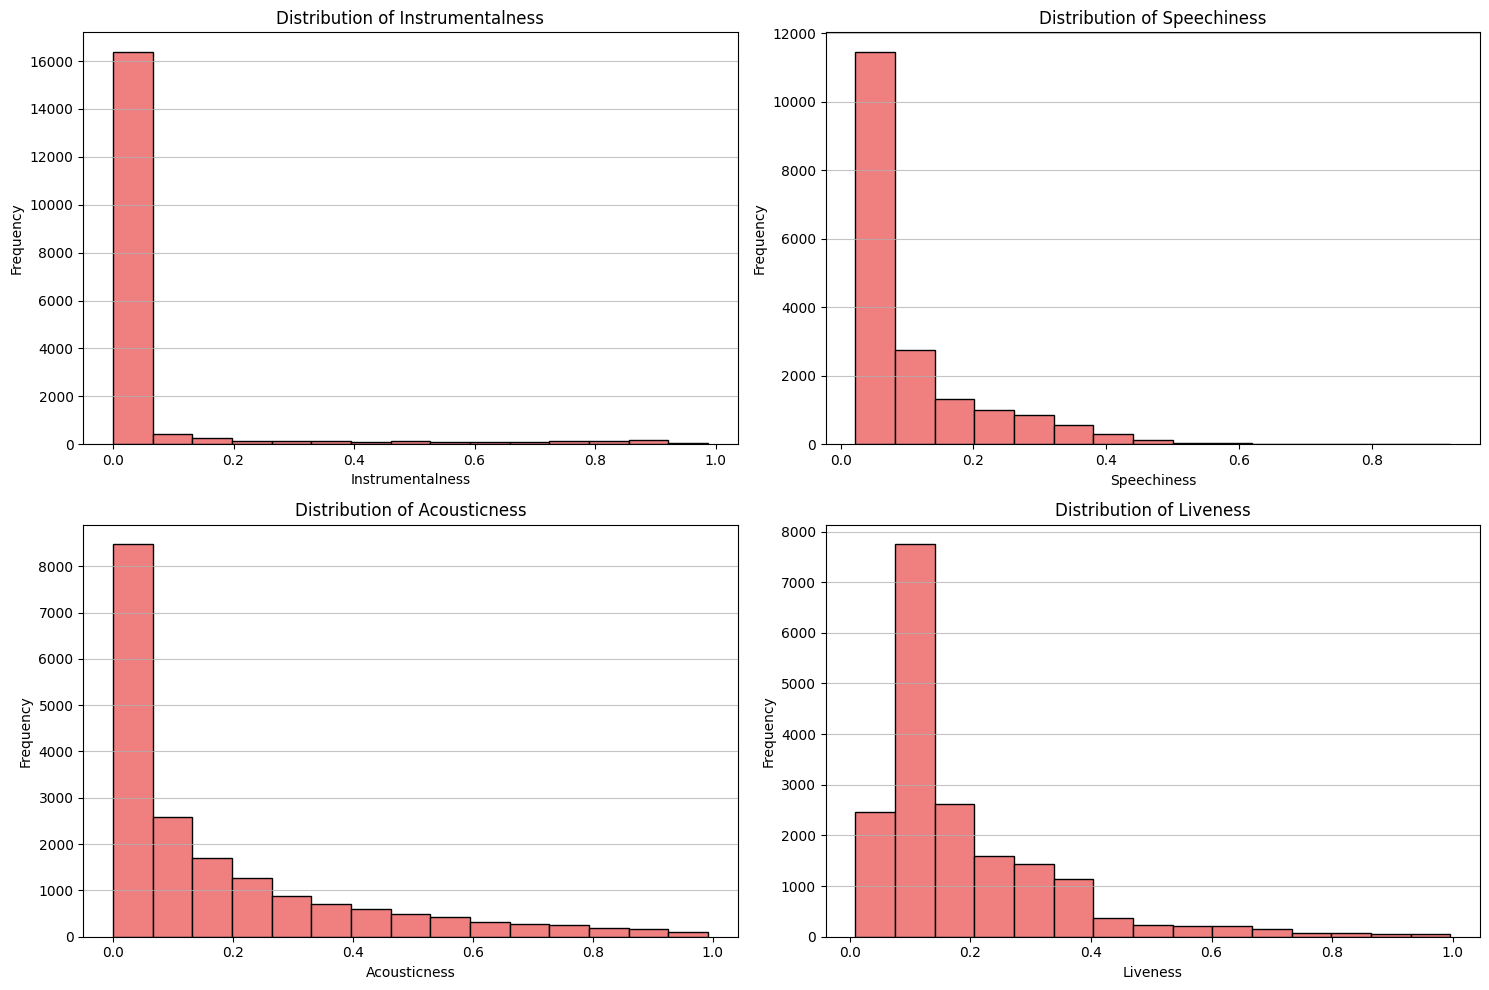

In [8]:
fig, ax = plt.subplots(nrows=5, ncols=2, figsize=(15, 10))
features = ['danceability', 'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
for i, feature in enumerate(features):
    row = i // 2
    col = i % 2

    ax[row, col].boxplot(data[feature].dropna(), vert=False, )
    ax[row, col].set_title(f'Distribution of {feature.capitalize()}')
    ax[row, col].set_xlabel(feature.capitalize())
    ax[row, col].set_ylabel('Frequency')
    ax[row, col].grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

subset_features = [ 'instrumentalness','speechiness' ,'acousticness', 'liveness']

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))
for i, feature in enumerate(subset_features):
    row = i // 2
    col = i % 2

    ax[row, col].hist(data[feature].dropna(), bins=15, color='lightcoral', edgecolor='black')
    ax[row, col].set_title(f'Distribution of {feature.capitalize()}')
    ax[row, col].set_xlabel(feature.capitalize())
    ax[row, col].set_ylabel('Frequency')
    ax[row, col].grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.show()

### Investigating correlations between atributes


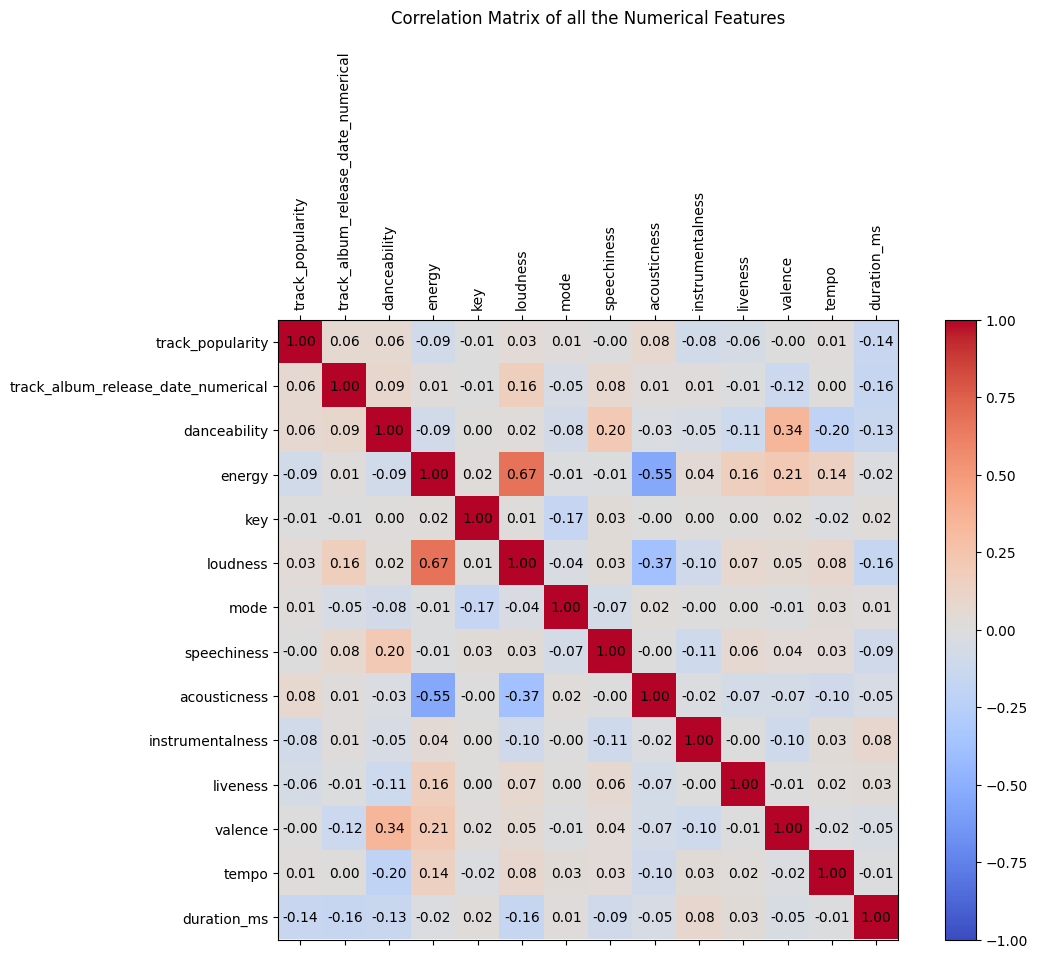

In [9]:

#convert release date to numerical format
data['track_album_release_date_numerical'] = pd.to_datetime(data['track_album_release_date'], errors='coerce').astype(int) / 10**9  # convert to Unix timestamp

numerical_features = [ 'track_popularity', 'track_album_release_date_numerical', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']



correlation_matrix = data[numerical_features].corr()

plt.figure(figsize=(12, 8))
cax = plt.matshow(correlation_matrix, fignum=1, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(cax)
plt.xticks(range(len(numerical_features)), numerical_features, rotation=90)
plt.yticks(range(len(numerical_features)), numerical_features)
plt.title('Correlation Matrix of all the Numerical Features', pad=20)
#add annotations for correlation values
for (i, j), val in np.ndenumerate(correlation_matrix.values):
    if val != 0:
        plt.text(j, i, f'{val:.2f}', ha='center', va='center', color='black')
plt.show()



/var/folders/0z/hxhcd0ss4k5fh2nxt641r6gm0000gn/T/ipykernel_60001/2660465201.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  correlation_matrix_focused = correlation_matrix.applymap(lambda x: x if abs(x) >= 0.25 and x != 1 else 0)


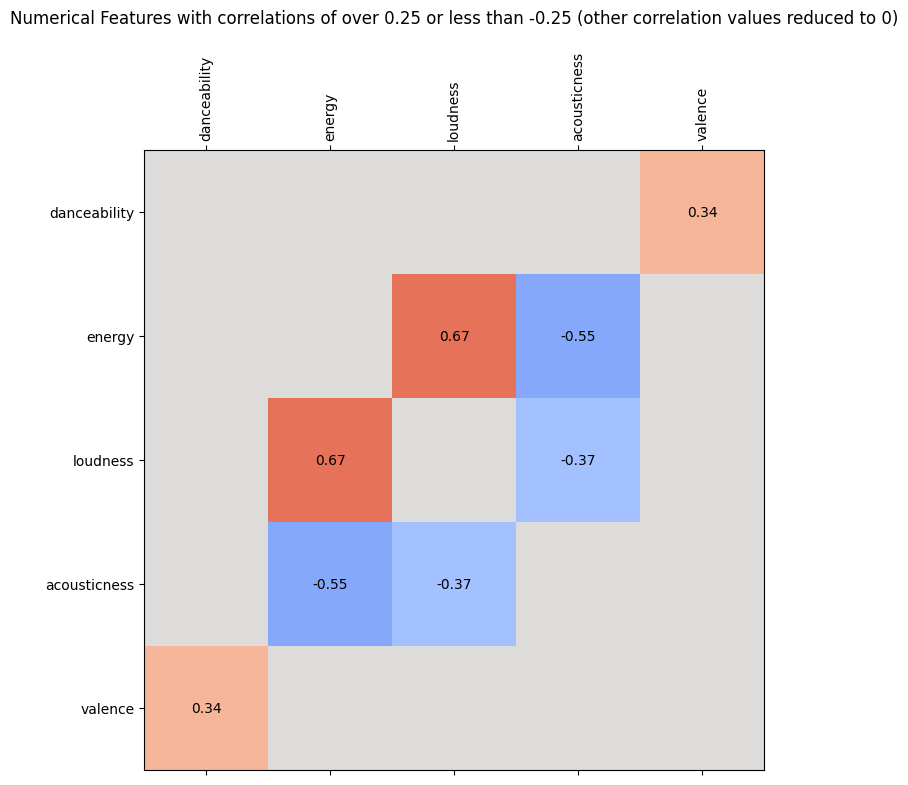

In [10]:

correlation_matrix = data[numerical_features].corr()

# convert all values that are 1, or less than 0.25 and greater than -0.25 into 0, and keep others unchanged
correlation_matrix_focused = correlation_matrix.applymap(lambda x: x if abs(x) >= 0.25 and x != 1 else 0)
# only keep rows and columns where there is at least one non-zero value
correlation_matrix_focused = correlation_matrix_focused.loc[(correlation_matrix_focused != 0).any(axis=1), (correlation_matrix_focused != 0).any(axis=0)]

numerical_features = correlation_matrix_focused.columns.tolist()

plt.figure(figsize=(12, 8))
plt.matshow(correlation_matrix_focused, fignum=1, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(numerical_features)), numerical_features, rotation=90)
plt.yticks(range(len(numerical_features)), numerical_features)
plt.title('Numerical Features with correlations of over 0.25 or less than -0.25 (other correlation values reduced to 0)', pad=20)
#add annotations for correlation values
for (i, j), val in np.ndenumerate(correlation_matrix_focused.values):
    if val != 0:
        plt.text(j, i, f'{val:.2f}', ha='center', va='center', color='black')
plt.show()


## The key insights drawn from EDA and potential challenges with the dataset (e.g., class imbalance, highly correlated features).

### Data Observations

Overall, the data is pretty clean and does not have that many missing values. Out of the 18454 tracks, only 260 of them have missing values for both the lyrics and language column. Even though the actual lyrics field is missing, each track still contains values for other key features connected to the lyrics data such as its, 'energy', 'speechiness', or 'valence'.

The track genres are fairly evenly distributed, with only genres of pop, rock, rap, r&b, latin and edm, appearing in the data set. There is bit more pop songs than other genres, and less of edm and latin songs, as seen in figure above. For popularity scores the distribution looks bimodal, with peak frequency popularity scores at 0 and around 50-60. Additionally, very few songs have over 90 populariy score value.

The tracks duration feature looks fairly normally distributed around mean of close to 200 seconds. Out of the 18454 tracks in datasets, over 15000 of them are in the english language, and the remaining have coming from 34 different languages. Overall, most of the tracks have word count less than 1000 words (assuming word count can be found by performing .split() on each lyrics string on spaces), but there also some with word counts going as high as 5000 words.

Looking at the various attributes of the tracks describing their sounds, such as 'danceability', 'energy', 'key', or 'loudness', we see various different distributions for them. For attributes, such as 'instrumentalness','speechiness' ,'acousticness', and 'liveness', we see a large variance of outlier point, and with most of the values around a specific value (see boxplots above). Most other sound describing numerical attributes also have outlier points, though not to the varying extent as the prior mentioned attributes.

### Correlations

Heatmaps above show correlations between all the numerical features. Our target feature is the popularity score, and none of other features show strong correlations towards with it. Duration has the highest correlation with popularity, with a correlation value of -0.14. This can be seen in the first heatmap above.

The second heatmap above shows, all the correlations, that have correlation absolute values of over .25. Loudness and accousticness both have strong correlations with energy, with values of .67 and -.55, respectively. Additionally, accousticness and loudness have correlation value of -.37, and valence and danceablity have a correlation value of .34.

### Challenges

A challenge is how none of our features seem to be correlated strongly with the target variable of music popularity. There is also alot of outliers for most of the numerical features, which might pose further challenges.

There is also the issue of how some tracks are missing their lyrical data, but this only applies to a small number of them.


## Data Preprocessing Requirements


## Handle Missing/Incorrect Values

### Dealing With Song Lyrics

The lyric column values are not consistent, and the inconsistencies are handled below.

First, check for suspicious values by printing out all rows where the lyric value length is less than 30. Sometimes it is valid, but other times it is "Instrumental" to mean the song is intrumental.

By looking through all lyric values with length less than 30, it can be figured out which values correspond to intrumental tracks, and which correspond to having unknown lyrics (not done yet by someone).

In [11]:
# Find lyric values that may need to be dealt with.

check = data[data['lyrics'].str.len() < 30]

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

check[['track_id', 'lyrics']]

,track_id,lyrics
316,090rX2ouW974AT3dFCxJpc,(instrumental)
569,0CNuKKi6MHrr8DqYtpzbCD,NA NA
615,0DbRkFE2KAyNXnKzD9inpV,Instrumental
917,0HeTpk89fOwfTBVL5d2acE,Play nice
1118,0k4A0wcdZLY0OSQ1ugfi3J,Don't Lyrics
1139,0kELB413kQh5WBO2acvnfW,"Letra de ""Calientito Boyz"""
1464,0oHO4SzupiDdp9OU1hu8AK,G-Get dirty-y!
1884,0tnFKjEEsjD3AVShRgtIun,Just vibin' They lovin'
2226,0yHOOuKhe57iSzS2TbxSKN,NA NA
3416,1IKkETDWIYawx8zgRaQwPL,NA NA


In [12]:
pd.reset_option('all')

/var/folders/0z/hxhcd0ss4k5fh2nxt641r6gm0000gn/T/ipykernel_60001/1012653977.py:1: FutureWarning: data_manager option is deprecated and will be removed in a future version. Only the BlockManager will be available.
  pd.reset_option('all')
/var/folders/0z/hxhcd0ss4k5fh2nxt641r6gm0000gn/T/ipykernel_60001/1012653977.py:1: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  pd.reset_option('all')


### Get all songs where the lyrics are unknown

When the lyrics are unknown, it could either be an intrumental track, or have actual lyrics. I verified that it could be either case by listening to random songs with values `[NaN, "NA NA", "NA NA NA", "Soon. ;)"]`. Sometimes the songs had lyrics, and sometimes they didn't. There aren't many cases where the lyrics are unknown, so it is easier to delete these cases.

Note that NaN comes from pandas interpreting "NA" as NaN. The values "NA NA" and "NA NA NA" also mean NaN, but pandas doesn't figure this out, so `data_lyrics_na` is created by merging all lyric values of NaN with values in the list `lyrics_extra_missing_values`.

In [13]:
lyrics_extra_missing_values = ["NA NA", "NA NA NA", "Soon. ;)"]

data_lyrics_na = data[data['lyrics'].isnull() | data['lyrics'].isin(lyrics_extra_missing_values)]
data_lyrics_na

,track_id,track_name,track_artist,lyrics,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,language,lyric_words,track_album_release_date_numerical
111,03bF2V5oDkhYDrMY6m7ZLB,Payback - Original Mix,Sandro Silva,NaN,25,2gTQ5glXXCHWIm1FIhyIXt,Payback,2013-11-25,Gym (Melbourne Bounce/Progressive House),5BqOZpVEqRDfZScvW1QUyA,...,0.0526,0.000873,0.3840,0.1120,0.2300,127.870,277509,NaN,NaN,1.385338e+09
115,03L9G5TQGdhASEknspRIZQ,BARRACA (feat. MC Pikachu),Garmiani,NaN,50,2s4IDihyyANNAeV3eYnnwc,BARRACA (feat. MC Pikachu),2019-05-03,"Festival Music 2019 - Warm Up Music (EDM, Big ...",73uj4YmsC7SJ6SbUMTvf07,...,0.0747,0.200000,0.3800,0.3510,0.9290,128.031,150020,NaN,NaN,1.556842e+09
125,03uSlN1JqW0MI6OCl7UQEa,You Don't Know,Psalm Trees,NaN,58,1ujIpuxtWkMjAnVn1QeFvt,You Don't Know What Love Is,2019-08-30,Lo-Fi Beats,37i9dQZF1DWWQRwui0ExPn,...,0.0470,0.673000,0.8490,0.1430,0.8210,88.015,166364,NaN,NaN,1.567123e+09
199,05UpUTOoVV6PVjfIhjretZ,Conte a Todos,Sango,NaN,41,5Olya3n1lRhRU7NxNihquQ,"De Mim, Pra Você",2017-03-15,POPTIMISM,6lWMi4lPiiPwDqn8ZpeyAY,...,0.3020,0.144000,0.1900,0.3380,0.6340,130.067,192000,NaN,NaN,1.489536e+09
465,0BjvqQdUUB2WzUncxxvIRh,entheogen,Nohidea,NaN,52,1wHWgiK24ERtcIGFN0eBK3,Departures,2018-08-18,Lofi Hip-Hop,37i9dQZF1DX36Xw4IJIVKA,...,0.0621,0.258000,0.0075,0.1340,0.0853,78.305,108942,NaN,NaN,1.534550e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18055,7qBj3Uyq1viGgNVHMwY00D,Go Hard,Quintino,NA NA,0,16H4sLgjJTsSvjPT5iqTTY,Go Hard,2014-05-30,Fitness Workout Electro | House | Dance | Prog...,6KnQDwp0syvhfHOR4lWP7x,...,0.0517,0.000657,0.7570,0.0567,0.0605,128.007,275583,vi,2.0,1.401408e+09
18077,7qoyy6rBNCGN27vOEZKgbr,Say U Won't,Brasstracks,NaN,40,4dj2CRLWvdFgEzsVtc2qr6,Good Love,2016-08-19,Urban Contemporary,4425cRh83Uzor4qCRfM9lb,...,0.1540,0.001760,0.9100,0.0842,0.6290,148.992,189945,NaN,NaN,1.471565e+09
18081,7qrBYrivpvfXUPBMmqh3dA,5:32pm,The Deli,NaN,70,5GlqARIKJdOkuXKgvdouwz,Vibes 2,2016-10-17,Sunny Beats,37i9dQZF1DXbtuVQL4zoey,...,0.0487,0.686000,0.9340,0.0762,0.5480,86.383,136914,NaN,NaN,1.476662e+09
18146,7sCIdsYQ8Nxoj6TjB1Eb7P,Toulouse - Original Mix,Nicky Romero,NaN,0,6FypcAZhJmCJJB8yEajt71,Toulouse,2012-01-02,2011-2014 House,53Ga3Xt9fumdJfhNNSBvzU,...,0.1010,0.033800,0.6900,0.2180,0.2660,128.001,365626,NaN,NaN,1.325462e+09


### Get all songs which are intrumentals

Any value in the list `lyrics_intrumental_values` below. That list was manually created by analyzing lyric values of length less than 30. There is only one instance of "Don't Lyrics", and was manually verified to be an intrumental track.

In [14]:
lyrics_intrumental_values = ["(instrumental)", "Instrumental", "Don't Lyrics", "INSTRUMENTAL", "Instrumental Instrumental", "INSTRUMENTAL ONLY", "(Instrumental & scatting)"]

data_intrumental = data[data['lyrics'].isin(lyrics_intrumental_values)]
data_intrumental

,track_id,track_name,track_artist,lyrics,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,language,lyric_words,track_album_release_date_numerical
316,090rX2ouW974AT3dFCxJpc,"Axel F - From ""Beverly Hills Cop"" Soundtrack",Harold Faltermeyer,(instrumental),38,3rvuKtdAV2z6Gza7iZxcyd,Totally '80s For Kids,2010-01-01,80s Pop & Rock Hits and Album Tracks,0XOIK4m26aeYSD61E5nSVW,...,0.0770,0.052500,0.9280,0.0934,0.5500,117.499,180373,ro,1.0,1.262304e+09
615,0DbRkFE2KAyNXnKzD9inpV,Catherine Of Aragon,Rick Wakeman,Instrumental,2,61CleyhcaLoE0xYyphY8S3,The Six Wives Of Henry VIII,1973-01-23,Progressive Rock / Metal - Rock /Metal Progre...,7GhTpb4eOp6403Bmgqz3db,...,0.0335,0.419000,0.8710,0.3270,0.0923,104.737,229147,ro,1.0,9.659520e+07
1118,0k4A0wcdZLY0OSQ1ugfi3J,Paris,Kungs,Don't Lyrics,59,2UJpW4aO9nXGEh7arP5uW8,Paris,2019-11-29,💊ELECTRO-HOUSE-TECH💊,0AFYmoSuoMQiGGjzvBwr6u,...,0.2560,0.005430,0.9620,0.2730,0.0537,124.005,201290,en,2.0,1.574986e+09
3481,1jf4zm3rN0CtpHED3g8umw,The Alphabeat - Radio Edit,David Guetta,Instrumental,30,4mgttktrNENk1Z2d46jS3H,The Alphabeat (Radio Edit),2012-03-23,Gym (Melbourne Bounce/Progressive House),5BqOZpVEqRDfZScvW1QUyA,...,0.2920,0.022200,0.6590,0.6950,0.1090,121.965,205591,ro,1.0,1.332461e+09
5818,2J8XWGtQb2PFtuHjyaNow3,Silence,Philanthrope,Instrumental,55,4gLd0XyVlQ89K7ycaLHdgt,Waking Dreams,2018-06-21,Lush Lofi,37i9dQZF1DXc8kgYqQLMfH,...,0.0560,0.838000,0.9250,0.0891,0.6870,151.971,105101,ro,1.0,1.529539e+09
7619,3BzfDBrjyvLLyDnhTynkOM,Borneo Jungle Oasis For Deep Sleep With Nature...,Relax Meditate Sleep,Instrumental,1,7zVNlLfb6CSgCe5AMDhc74,Relaxing Nature Sounds,2009-11-15,Tropical Nights,37i9dQZF1DX0ES2mnOVvai,...,0.3450,0.390000,0.4640,0.2480,0.0718,140.790,360098,ro,1.0,1.258243e+09
10823,4n6z0yh2ZpoGh0RNyGVu52,One Day They'll Know (ODESZA Remix),Pretty Lights,INSTRUMENTAL,56,0pbCJhGv304qQ16xWvqyBH,A Color Map of the Sun (Remixes),2013-12-10,Indie Poptimism,2QiMewRbSavfZ9MSAYz2h6,...,0.0317,0.005910,0.6240,0.1600,0.2940,140.026,260571,id,1.0,1.386634e+09
10936,4oJnPMMBftqQRjWFqwvblo,Funky Vodka,TJR,Instrumental Instrumental,32,5zjyrzATk3o7Ak26genj9U,Funky Vodka,2013-01-01,Fitness Workout Electro | House | Dance | Prog...,6KnQDwp0syvhfHOR4lWP7x,...,0.0554,0.000193,0.1250,0.0155,0.7820,126.989,359957,ro,2.0,1.356998e+09
10963,4OuuTwky6Lupc7zDJNtig6,Uitzicht,Bakermat,Instrumental,54,0Ut8OHyOMZ0uAg7MboCcvy,Uitzicht - EP,2013-06-21,Tropical Morning,0vbtbmyihyvl2MVYrdKdGw,...,0.0656,0.016900,0.8910,0.0614,0.6600,125.987,308929,ro,1.0,1.371773e+09
11414,4uPGRSEYtAeKgdRQtveMnP,Deep Fear - Phobia Radio Edit,Sidekick,INSTRUMENTAL,0,7xg77MEQ20yJCKy4assxs6,Dance Chart [Online Version] [Autumn 2009],2009-08-31,Electro/Progressive/Club House,1HtnPDj2V126xB9tJP786P,...,0.0642,0.037800,0.9160,0.0686,0.0399,126.032,208400,id,1.0,1.251677e+09


### Process data song lyrics

Remove all songs with unknown lyrics (the rows of `data_lyrics_na`). There aren't that many rows versus our entire dataset size, and there isn't any way to known which are intrumentals or not without manually checking every single one.

For dealing with intrumental songs, a new "Intrumental" boolean column will be added.

In [15]:
# Drop all rows with unknown lyric values.
print("Shape after drop all unknown lyric values:",data.shape)
print("Shape of unknown lyric values dataframe to drop from main dataframe:",data_lyrics_na.shape)
data.drop(data_lyrics_na.index, inplace=True)
print("Shape after drop all unknown lyric values:",data.shape)

# Add an `intrumental` column.
data['intrumental'] = False
data.loc[data['lyrics'].isin(lyrics_intrumental_values), 'intrumental'] = True
# Make the intrumental tracks have the lyrics as the empty string "", since there are no words.
data.loc[data['lyrics'].isin(lyrics_intrumental_values), 'lyrics'] = ""
print("Shape of intrumental tracks:",data[data['intrumental'] == True].shape)
data[data['intrumental'] == True]

Shape after drop all unknown lyric values: (18454, 27)
Shape of unknown lyric values dataframe to drop from main dataframe: (281, 27)
Shape after drop all unknown lyric values: (18173, 27)
Shape of intrumental tracks: (17, 28)


,track_id,track_name,track_artist,lyrics,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,...,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,language,lyric_words,track_album_release_date_numerical,intrumental
316,090rX2ouW974AT3dFCxJpc,"Axel F - From ""Beverly Hills Cop"" Soundtrack",Harold Faltermeyer,,38,3rvuKtdAV2z6Gza7iZxcyd,Totally '80s For Kids,2010-01-01,80s Pop & Rock Hits and Album Tracks,0XOIK4m26aeYSD61E5nSVW,...,0.052500,0.9280,0.0934,0.5500,117.499,180373,ro,1.0,1.262304e+09,True
615,0DbRkFE2KAyNXnKzD9inpV,Catherine Of Aragon,Rick Wakeman,,2,61CleyhcaLoE0xYyphY8S3,The Six Wives Of Henry VIII,1973-01-23,Progressive Rock / Metal - Rock /Metal Progre...,7GhTpb4eOp6403Bmgqz3db,...,0.419000,0.8710,0.3270,0.0923,104.737,229147,ro,1.0,9.659520e+07,True
1118,0k4A0wcdZLY0OSQ1ugfi3J,Paris,Kungs,,59,2UJpW4aO9nXGEh7arP5uW8,Paris,2019-11-29,💊ELECTRO-HOUSE-TECH💊,0AFYmoSuoMQiGGjzvBwr6u,...,0.005430,0.9620,0.2730,0.0537,124.005,201290,en,2.0,1.574986e+09,True
3481,1jf4zm3rN0CtpHED3g8umw,The Alphabeat - Radio Edit,David Guetta,,30,4mgttktrNENk1Z2d46jS3H,The Alphabeat (Radio Edit),2012-03-23,Gym (Melbourne Bounce/Progressive House),5BqOZpVEqRDfZScvW1QUyA,...,0.022200,0.6590,0.6950,0.1090,121.965,205591,ro,1.0,1.332461e+09,True
5818,2J8XWGtQb2PFtuHjyaNow3,Silence,Philanthrope,,55,4gLd0XyVlQ89K7ycaLHdgt,Waking Dreams,2018-06-21,Lush Lofi,37i9dQZF1DXc8kgYqQLMfH,...,0.838000,0.9250,0.0891,0.6870,151.971,105101,ro,1.0,1.529539e+09,True
7619,3BzfDBrjyvLLyDnhTynkOM,Borneo Jungle Oasis For Deep Sleep With Nature...,Relax Meditate Sleep,,1,7zVNlLfb6CSgCe5AMDhc74,Relaxing Nature Sounds,2009-11-15,Tropical Nights,37i9dQZF1DX0ES2mnOVvai,...,0.390000,0.4640,0.2480,0.0718,140.790,360098,ro,1.0,1.258243e+09,True
10823,4n6z0yh2ZpoGh0RNyGVu52,One Day They'll Know (ODESZA Remix),Pretty Lights,,56,0pbCJhGv304qQ16xWvqyBH,A Color Map of the Sun (Remixes),2013-12-10,Indie Poptimism,2QiMewRbSavfZ9MSAYz2h6,...,0.005910,0.6240,0.1600,0.2940,140.026,260571,id,1.0,1.386634e+09,True
10936,4oJnPMMBftqQRjWFqwvblo,Funky Vodka,TJR,,32,5zjyrzATk3o7Ak26genj9U,Funky Vodka,2013-01-01,Fitness Workout Electro | House | Dance | Prog...,6KnQDwp0syvhfHOR4lWP7x,...,0.000193,0.1250,0.0155,0.7820,126.989,359957,ro,2.0,1.356998e+09,True
10963,4OuuTwky6Lupc7zDJNtig6,Uitzicht,Bakermat,,54,0Ut8OHyOMZ0uAg7MboCcvy,Uitzicht - EP,2013-06-21,Tropical Morning,0vbtbmyihyvl2MVYrdKdGw,...,0.016900,0.8910,0.0614,0.6600,125.987,308929,ro,1.0,1.371773e+09,True
11414,4uPGRSEYtAeKgdRQtveMnP,Deep Fear - Phobia Radio Edit,Sidekick,,0,7xg77MEQ20yJCKy4assxs6,Dance Chart [Online Version] [Autumn 2009],2009-08-31,Electro/Progressive/Club House,1HtnPDj2V126xB9tJP786P,...,0.037800,0.9160,0.0686,0.0399,126.032,208400,id,1.0,1.251677e+09,True


## Check For Duplicates

The `track_id` corresponds to the unique URL for a Spotify song. If any duplicate exists, then it would have the same track ID.

Below, it is shown that there are no duplicate values in the `track_id` column, so there are no duplicates in the dataset.

In [16]:
data.duplicated(subset=['track_id']).any()

np.False_

## Normalize Columns

The columns in the list `numerical_normalize_columns` are the numerical columns that should be normalized.

In [17]:
# Normalize numerical columns that should be normalized.
numerical_normalize_columns = ['danceability', 'energy','loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'track_album_release_date_numerical', 'lyric_words']

numerical_to_normalize = data[numerical_normalize_columns]
numerical_normalized = (numerical_to_normalize - numerical_to_normalize.min()) / (numerical_to_normalize.max() - numerical_to_normalize.min())

numerical_normalized

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,track_album_release_date_numerical,lyric_words
0,0.655852,0.390827,0.681000,0.001340,0.281249,0.011854,0.080414,0.571136,0.338981,0.418893,0.944373,0.024328
1,0.216686,0.877962,0.830868,0.024341,0.011793,0.010071,0.342212,0.407663,0.554509,0.703040,0.993706,0.019971
2,0.844728,0.646090,0.753108,0.216168,0.004353,0.007325,0.486135,0.655900,0.422702,0.474513,0.956059,0.076071
3,0.358053,0.367436,0.800495,0.013064,0.694556,0.000000,0.057812,0.408672,0.460508,0.434589,0.978917,0.061728
4,0.746234,0.885081,0.908094,0.020657,0.037297,0.000000,0.130382,0.242172,0.525080,0.331882,0.999064,0.063544
...,...,...,...,...,...,...,...,...,...,...,...,...
18449,0.420626,0.796603,0.801648,0.073024,0.005593,0.000000,0.330049,0.212908,0.513742,0.363772,0.983004,0.047749
18450,0.981460,0.596258,0.789105,0.175971,0.067841,0.000006,0.207411,0.652872,0.524922,0.469930,0.985132,0.113653
18451,0.396292,0.532188,0.782552,0.005136,0.720766,0.000434,0.107070,0.662963,0.594033,0.327858,0.980941,0.023057
18452,0.829664,0.660327,0.825778,0.045668,0.144152,0.000000,0.063488,0.817354,0.409319,0.395123,0.972847,0.113653


# Add more Features


In [18]:
data["track_popularity_categorical"] = pd.cut(data["track_popularity"], bins=[-1, 50, 100], labels=["low", "high"])
print("Value counts for the new categorical track popularity column:")
print(data["track_popularity_categorical"].value_counts())

Value counts for the new categorical track popularity column:
track_popularity_categorical
low     9866
high    8307
Name: count, dtype: int64


In [19]:
data = data[data['track_popularity'] != 0]
print(data['track_popularity'].value_counts())

# Update the original dataframe with the normalized columns.
for col in numerical_normalize_columns:
    data[col] = numerical_normalized[col]

# Move the lyrics column to the end.
data = data[[column for column in data.columns if column != 'lyrics'] + ['lyrics']]

data.to_csv('./../data/preprocessed/spotify_songs_preprocessed.csv', index=False)


track_popularity
1      389
57     361
55     346
60     345
51     345
      ... 
94       5
97       3
95       2
100      1
99       1
Name: count, Length: 99, dtype: int64
